# Características RoCoLe — GLCM e índices RGB

Objetivo: medir textura (GLCM) y color (índices RGB) sobre las fotos ya partidas en train/val/test, primero en **una** hoja de train como comprobación, y después en todo el inventario.

Por ahora usamos la **fotografía completa** (hoja + fondo). Más adelante contrastaremos con una máscara de hoja. No entrenamos modelos aquí: eso va en los cuadernos 03 y 04.

Responsables: Víctor y Gio.


## Llegar al índice y fijar la semilla

Usamos la ruta al índice featured (ya tiene `split` y `photo_path`) y una semilla fija para cualquier muestreo.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from pycocotools.coco import COCO
from skimage.feature import graycomatrix, graycoprops
from tqdm.auto import tqdm


D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
repo_root = Path("../..").resolve()
featured_dir = repo_root / "data" / "featured" / "rocole"
index_path = featured_dir / "index.csv"
seed = 42

print("repo_root:", repo_root)
print("index_path:", index_path)
print("existe:", index_path.exists())
seed


repo_root: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe
index_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\index.csv
existe: True


42

## Cargar el índice partido

El índice es la mesa de trabajo: una fila por foto, con etiqueta, partición y ruta a la imagen curada. No rehacemos el split.


In [3]:
rocole_index = pd.read_csv(index_path)

print("filas:", len(rocole_index))
print("columnas:", list(rocole_index.columns))
rocole_index.head()


filas: 1481
columnas: ['File', 'plant_key', 'link_group', 'Binary.Label', 'Multiclass.Label', 'leaf_face', 'split', 'photo_path']


,File,plant_key,link_group,Binary.Label,Multiclass.Label,leaf_face,split,photo_path
0,C1P1H1.jpg,C1P1,74,healthy,healthy,H,train,data/curated/rocole/photos/C1P1H1.jpg
1,C1P2E2.jpg,C1P2,84,unhealthy,rust_level_2,E,train,data/curated/rocole/photos/C1P2E2.jpg
2,C1P2H1.jpg,C1P2,84,healthy,healthy,H,train,data/curated/rocole/photos/C1P2H1.jpg
3,C1P3E1.jpg,C1P3,95,healthy,healthy,E,train,data/curated/rocole/photos/C1P3E1.jpg
4,C1P3E2.jpg,C1P3,95,unhealthy,rust_level_2,E,train,data/curated/rocole/photos/C1P3E2.jpg


## Elegir una sola foto de train

Para verificar el camino basta con una hoja de aprender. No miramos val ni test todavía.


In [4]:
# rocole_index: mesa con File, split, photo_path y etiquetas

train_rows = rocole_index.loc[rocole_index["split"] == "train"].reset_index(drop=True)
sample_row = train_rows.iloc[0]

print("File:", sample_row["File"])
print("Binary.Label:", sample_row["Binary.Label"])
print("Multiclass.Label:", sample_row["Multiclass.Label"])
print("photo_path:", sample_row["photo_path"])
sample_row


File: C1P1H1.jpg
Binary.Label: healthy
Multiclass.Label: healthy
photo_path: data/curated/rocole/photos/C1P1H1.jpg


File                                           C1P1H1.jpg
plant_key                                            C1P1
link_group                                             74
Binary.Label                                      healthy
Multiclass.Label                                  healthy
leaf_face                                               H
split                                               train
photo_path          data/curated/rocole/photos/C1P1H1.jpg
Name: 0, dtype: object

## Abrir la fotografía completa

Leemos la imagen tal cual está en curated: hoja y fondo juntos. Si carga y se ve, el resto del cuaderno puede apoyarse en esa misma ruta.


ruta: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\curated\rocole\photos\C1P1H1.jpg
existe: True
tamaño: (2048, 1152) modo: RGB


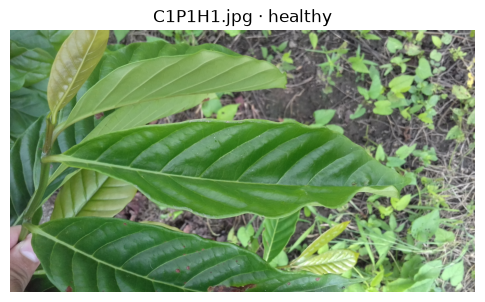

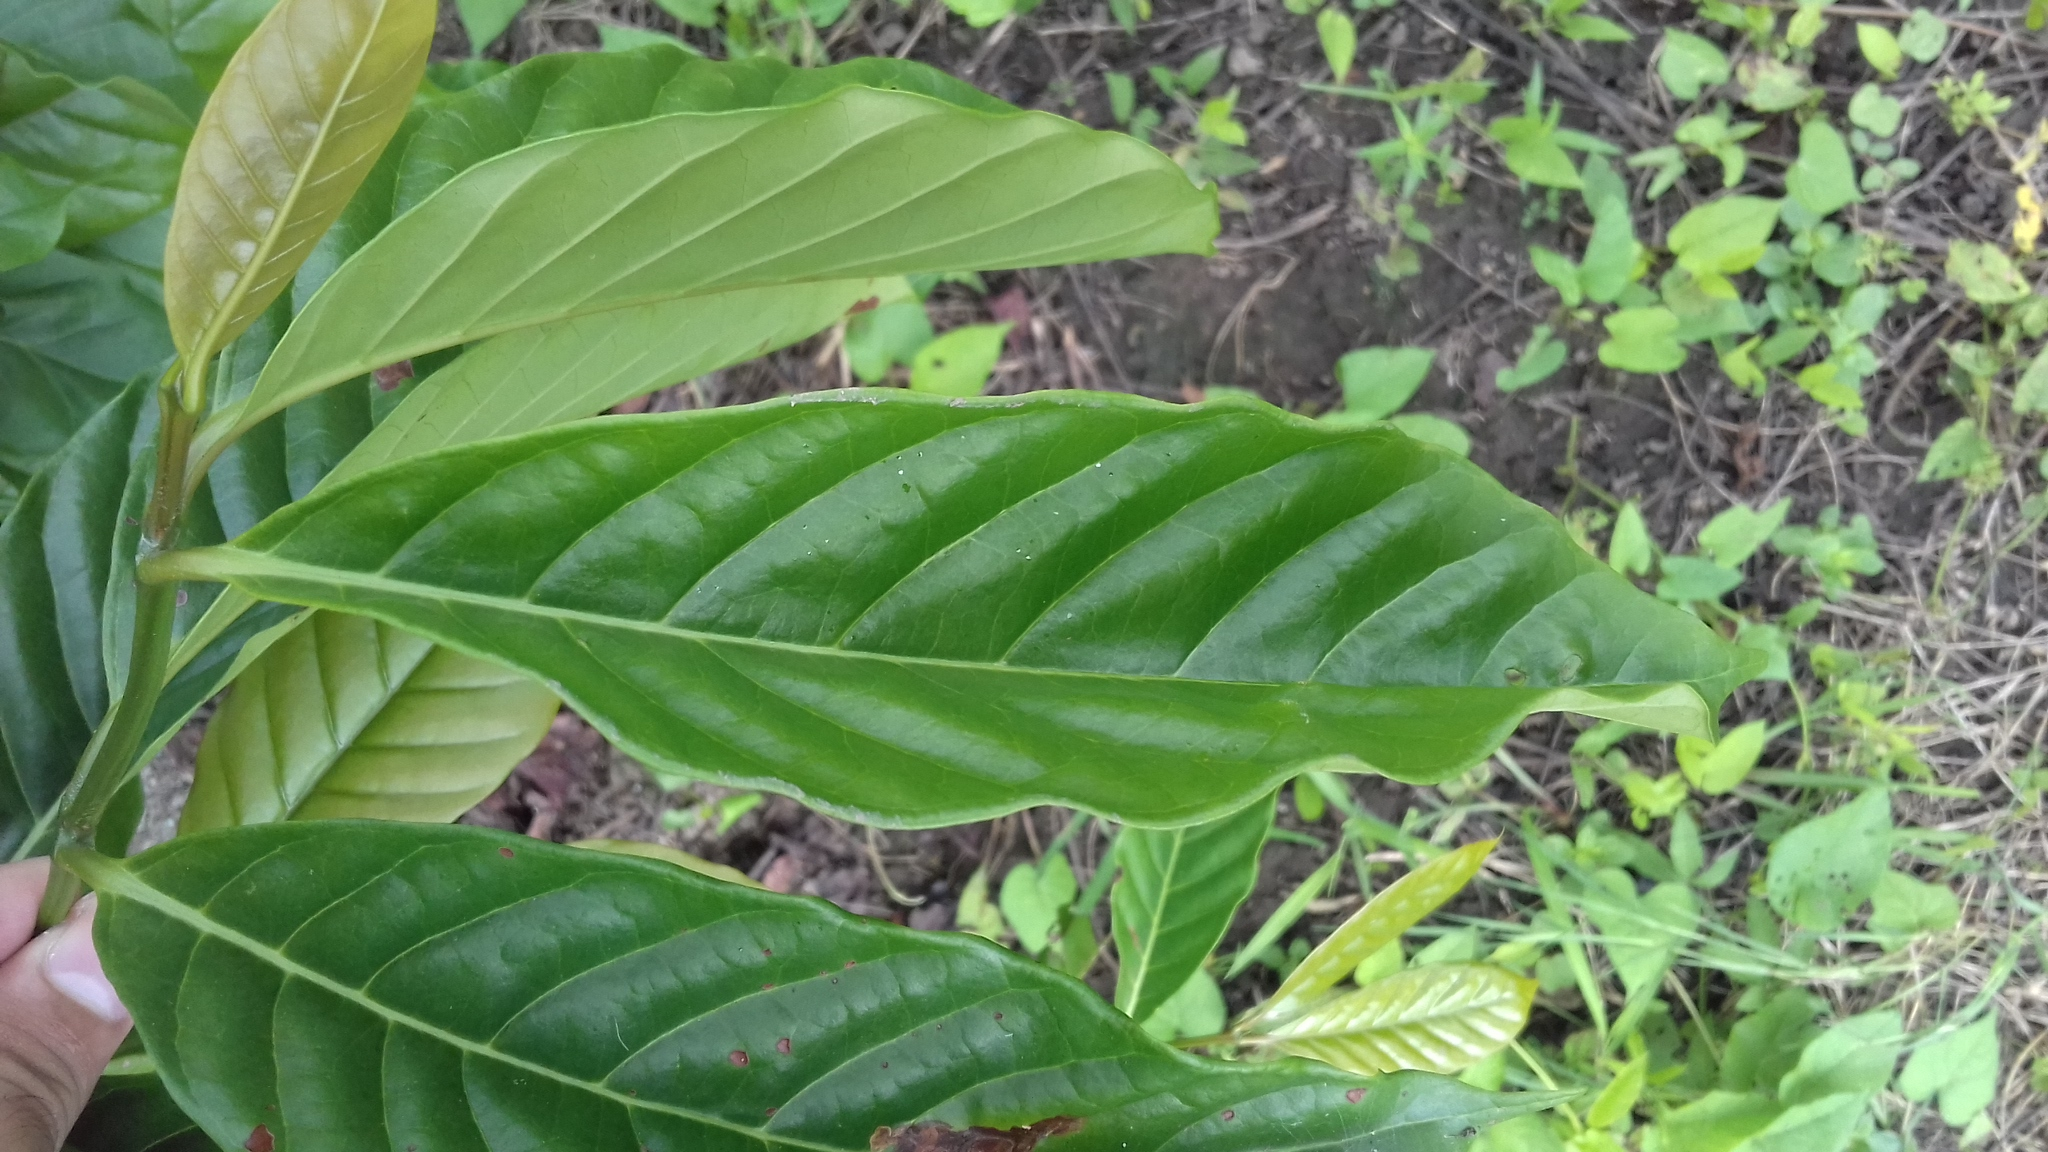

In [5]:
photo_path = repo_root / sample_row["photo_path"]
sample_image = Image.open(photo_path).convert("RGB")

print("ruta:", photo_path)
print("existe:", photo_path.exists())
print("tamaño:", sample_image.size, "modo:", sample_image.mode)
plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.axis("off")
plt.title(f"{sample_row['File']} · {sample_row['Binary.Label']}")
plt.show()
sample_image


## Pasar la foto a números

La imagen PIL no sirve para restas canal a canal. La convertimos a un arreglo float (0–255) para calcular los índices sin perder decimales.


In [6]:
# float antes de restas: evita truncar en los índices
sample_rgb = np.asarray(sample_image, dtype=np.float64)

print("forma:", sample_rgb.shape, "dtype:", sample_rgb.dtype)
print("min/max:", sample_rgb.min(), sample_rgb.max())
sample_rgb


forma: (1152, 2048, 3) dtype: float64
min/max: 0.0 255.0


array([[[ 98., 136., 121.],
        [ 99., 137., 122.],
        [101., 139., 124.],
        ...,
        [141., 171.,  71.],
        [139., 169.,  69.],
        [145., 176.,  73.]],

       [[ 96., 134., 119.],
        [ 96., 134., 119.],
        [101., 139., 124.],
        ...,
        [139., 169.,  73.],
        [139., 169.,  71.],
        [145., 175.,  75.]],

       [[101., 139., 124.],
        [102., 140., 125.],
        [102., 140., 125.],
        ...,
        [142., 171.,  79.],
        [146., 173.,  80.],
        [146., 173.,  80.]],

       ...,

       [[129., 109., 100.],
        [129., 109., 100.],
        [128., 108.,  99.],
        ...,
        [118., 115., 110.],
        [113., 108., 104.],
        [113., 108., 104.]],

       [[128., 108.,  99.],
        [129., 109., 100.],
        [130., 110., 101.],
        ...,
        [119., 116., 111.],
        [118., 115., 108.],
        [115., 112., 105.]],

       [[130., 110., 101.],
        [131., 111., 102.],
        [131., 1

## Separar rojo, verde y azul

Cada índice mira cómo se relacionan los tres canales. Sacamos red_channel, green_channel y blue_channel del arreglo float.


In [7]:
# sample_rgb: HxWx3 float

red_channel = sample_rgb[:, :, 0]
green_channel = sample_rgb[:, :, 1]
blue_channel = sample_rgb[:, :, 2]

print("red:", red_channel.shape, "green:", green_channel.shape, "blue:", blue_channel.shape)
red_channel, green_channel, blue_channel


red: (1152, 2048) green: (1152, 2048) blue: (1152, 2048)


(array([[ 98.,  99., 101., ..., 141., 139., 145.],
        [ 96.,  96., 101., ..., 139., 139., 145.],
        [101., 102., 102., ..., 142., 146., 146.],
        ...,
        [129., 129., 128., ..., 118., 113., 113.],
        [128., 129., 130., ..., 119., 118., 115.],
        [130., 131., 131., ..., 129., 125., 118.]], shape=(1152, 2048)),
 array([[136., 137., 139., ..., 171., 169., 176.],
        [134., 134., 139., ..., 169., 169., 175.],
        [139., 140., 140., ..., 171., 173., 173.],
        ...,
        [109., 109., 108., ..., 115., 108., 108.],
        [108., 109., 110., ..., 116., 115., 112.],
        [110., 111., 111., ..., 126., 122., 115.]], shape=(1152, 2048)),
 array([[121., 122., 124., ...,  71.,  69.,  73.],
        [119., 119., 124., ...,  73.,  71.,  75.],
        [124., 125., 125., ...,  79.,  80.,  80.],
        ...,
        [100., 100.,  99., ..., 110., 104., 104.],
        [ 99., 100., 101., ..., 111., 108., 105.],
        [101., 102., 102., ..., 121., 115., 108.]]

## ExG: exceso de verde

Normalizamos cada canal por la suma RGB (con `eps` para no dividir por cero) y calculamos ExG = 2g − r − b. Aún sin máscara: hoja y fondo juntos.


In [8]:
eps = 1e-8

channel_sum = red_channel + green_channel + blue_channel + eps
r = red_channel / channel_sum
g = green_channel / channel_sum
b = blue_channel / channel_sum
exg_map = 2.0 * g - r - b

print("exg_map:", exg_map.shape, "min/max:", exg_map.min(), exg_map.max())
exg_map


exg_map: (1152, 2048) min/max: -0.9999999997058824 1.9999999994444444


array([[ 0.14929577,  0.14804469,  0.1456044 , ...,  0.33942559,
         0.34482759,  0.34010152],
       [ 0.15186246,  0.15186246,  0.1456044 , ...,  0.33070866,
         0.33773087,  0.32911392],
       [ 0.1456044 ,  0.14441417,  0.14441417, ...,  0.30867347,
         0.30075188,  0.30075188],
       ...,
       [-0.03254438, -0.03254438, -0.03283582, ...,  0.0058309 ,
        -0.00307692, -0.00307692],
       [-0.03283582, -0.03254438, -0.03225806, ...,  0.00578035,
         0.01173021,  0.01204819],
       [-0.03225806, -0.03197674, -0.03197674, ...,  0.00531915,
         0.01104972,  0.01173021]], shape=(1152, 2048))

## NGRDI: verde contra rojo

NGRDI = (G − R) / (G + R + eps). Resalta dónde el verde gana al rojo, píxel a píxel.


In [9]:
# green_channel, red_channel, eps

ngrdi_map = (green_channel - red_channel) / (green_channel + red_channel + eps)

print("ngrdi_map:", ngrdi_map.shape, "min/max:", ngrdi_map.min(), ngrdi_map.max())
ngrdi_map


ngrdi_map: (1152, 2048) min/max: -0.9999999996666666 0.9999999997222222


array([[ 0.16239316,  0.16101695,  0.15833333, ...,  0.09615385,
         0.0974026 ,  0.09657321],
       [ 0.16521739,  0.16521739,  0.15833333, ...,  0.0974026 ,
         0.0974026 ,  0.09375   ],
       [ 0.15833333,  0.15702479,  0.15702479, ...,  0.09265176,
         0.0846395 ,  0.0846395 ],
       ...,
       [-0.08403361, -0.08403361, -0.08474576, ..., -0.01287554,
        -0.02262443, -0.02262443],
       [-0.08474576, -0.08403361, -0.08333333, ..., -0.01276596,
        -0.01287554, -0.01321586],
       [-0.08333333, -0.08264463, -0.08264463, ..., -0.01176471,
        -0.01214575, -0.01287554]], shape=(1152, 2048))

## VARI: verde, rojo y azul

VARI = (G − R) / (G + R − B + eps). Parecido al NGRDI, pero resta el azul en el denominador.


In [10]:
# green_channel, red_channel, blue_channel, eps

vari_map = (green_channel - red_channel) / (
    green_channel + red_channel - blue_channel + eps
)

print("vari_map:", vari_map.shape, "min/max:", vari_map.min(), vari_map.max())
vari_map


vari_map: (1152, 2048) min/max: -1.1538461534023667 1.3846153840828401


array([[ 0.33628319,  0.33333333,  0.32758621, ...,  0.12448133,
         0.12552301,  0.125     ],
       [ 0.34234234,  0.34234234,  0.32758621, ...,  0.12765957,
         0.12658228,  0.12244898],
       [ 0.32758621,  0.32478632,  0.32478632, ...,  0.12393162,
         0.11297071,  0.11297071],
       ...,
       [-0.14492754, -0.14492754, -0.1459854 , ..., -0.02439024,
        -0.04273504, -0.04273504],
       [-0.1459854 , -0.14492754, -0.14388489, ..., -0.02419355,
        -0.024     , -0.02459016],
       [-0.14388489, -0.14285714, -0.14285714, ..., -0.02238806,
        -0.02272727, -0.024     ]], shape=(1152, 2048))

## Mirar el mapa ExG

Una sola figura del exceso de verde sobre la foto de ejemplo, para ver si el índice se comporta como esperamos antes de resumir números.


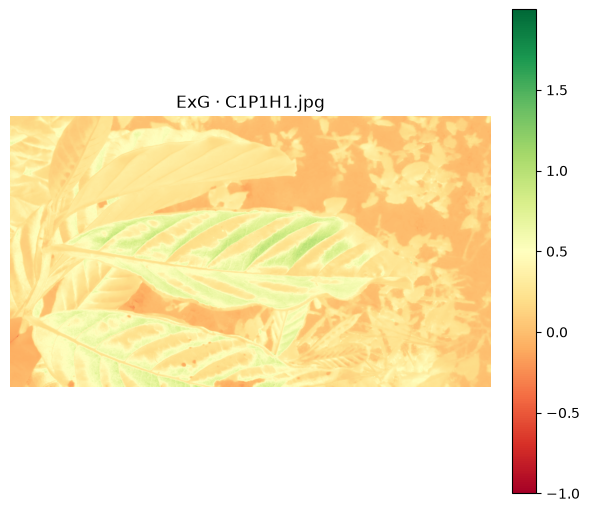

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_sample_exg_map.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole_sample_exg_map.png')

In [11]:
# exg_map: mapa ExG de la foto de ejemplo
results_dir = repo_root / "experiments" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
exg_fig_path = results_dir / "rocole_sample_exg_map.png"

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(exg_map, cmap="RdYlGn")
ax.set_title(f"ExG · {sample_row['File']}")
ax.axis("off")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(exg_fig_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", exg_fig_path)
exg_fig_path


## Resumir los tres índices

Media, desviación, mínimo y máximo de ExG, NGRDI y VARI sobre toda la foto (sin máscara). Chequeo numérico antes de GLCM e inventario.


In [12]:
# exg_map, ngrdi_map, vari_map

index_summary = {
    "exg": {
        "mean": float(exg_map.mean()),
        "std": float(exg_map.std()),
        "min": float(exg_map.min()),
        "max": float(exg_map.max()),
    },
    "ngrdi": {
        "mean": float(ngrdi_map.mean()),
        "std": float(ngrdi_map.std()),
        "min": float(ngrdi_map.min()),
        "max": float(ngrdi_map.max()),
    },
    "vari": {
        "mean": float(vari_map.mean()),
        "std": float(vari_map.std()),
        "min": float(vari_map.min()),
        "max": float(vari_map.max()),
    },
}

for name, stats in index_summary.items():
    print(
        f"{name}: mean={stats['mean']:.4f} std={stats['std']:.4f} "
        f"min={stats['min']:.4f} max={stats['max']:.4f}"
    )
index_summary


exg: mean=0.2615 std=0.2068 min=-1.0000 max=2.0000
ngrdi: mean=0.1414 std=0.1187 min=-1.0000 max=1.0000
vari: mean=0.2105 std=0.1707 min=-1.1538 max=1.3846


{'exg': {'mean': 0.26153037885135344,
  'std': 0.20683483907598796,
  'min': -0.9999999997058824,
  'max': 1.9999999994444444},
 'ngrdi': {'mean': 0.1414262157351517,
  'std': 0.11870452583154771,
  'min': -0.9999999996666666,
  'max': 0.9999999997222222},
 'vari': {'mean': 0.21046718150692867,
  'std': 0.17066530772717955,
  'min': -1.1538461534023667,
  'max': 1.3846153840828401}}

## Escala de grises para textura

La matriz de coocurrencia mira cómo cambian los grises vecinos, no el color. Pasamos `sample_image` a una sola banda.


In [13]:
# sample_image: foto PIL RGB de ejemplo

# una sola banda: la textura GLCM no usa color
gray = np.asarray(sample_image.convert("L"), dtype=np.uint8)

print("forma:", gray.shape, "dtype:", gray.dtype)
print("min/max:", int(gray.min()), int(gray.max()))
gray


forma: (1152, 2048) dtype: uint8
min/max: 7 254


array([[123, 124, 126, ..., 151, 149, 155],
       [121, 121, 126, ..., 149, 149, 155],
       [126, 127, 127, ..., 152, 154, 154],
       ...,
       [114, 114, 113, ..., 115, 109, 109],
       [113, 114, 115, ..., 116, 115, 112],
       [115, 116, 116, ..., 126, 122, 115]],
      shape=(1152, 2048), dtype=uint8)

## Bajar a 32 niveles de gris

Con 256 valores la matriz sería enorme. Cuantizamos a 32 niveles (`gray_level_count`) para que el GLCM sea manejable.


In [14]:
# gray: imagen en escala de grises 0–255
gray_level_count = 32

# reescalamos a enteros 0 … gray_level_count-1
quantized_gray = (
    gray.astype(np.float64) / 255.0 * (gray_level_count - 1)
).astype(np.uint8)

print("niveles pedidos:", gray_level_count)
print("valores únicos:", len(np.unique(quantized_gray)))
print("min/max:", int(quantized_gray.min()), int(quantized_gray.max()))
quantized_gray


niveles pedidos: 32
valores únicos: 31
min/max: 0 30


array([[14, 15, 15, ..., 18, 18, 18],
       [14, 14, 15, ..., 18, 18, 18],
       [15, 15, 15, ..., 18, 18, 18],
       ...,
       [13, 13, 13, ..., 13, 13, 13],
       [13, 13, 13, ..., 14, 13, 13],
       [13, 14, 14, ..., 15, 14, 13]], shape=(1152, 2048), dtype=uint8)

## Matriz de coocurrencia (una dirección)

Contamos qué tan a menudo un gris aparece al lado de otro: distancia 1, ángulo 0 (horizontal). Una sola dirección como comprobación.


In [15]:
# quantized_gray, gray_level_count

# distance=1, angle=0 rad (horizontal)
glcm = graycomatrix(
    quantized_gray,
    distances=[1],
    angles=[0],
    levels=gray_level_count,
)

print("forma GLCM:", glcm.shape)
glcm


forma GLCM: (32, 32, 1, 1)


array([[[[   0]],

        [[   0]],

        [[   0]],

        ...,

        [[   0]],

        [[   0]],

        [[   0]]],


       [[[   0]],

        [[  46]],

        [[  14]],

        ...,

        [[   0]],

        [[   0]],

        [[   0]]],


       [[[   0]],

        [[  17]],

        [[ 463]],

        ...,

        [[   0]],

        [[   0]],

        [[   0]]],


       ...,


       [[[   0]],

        [[   0]],

        [[   0]],

        ...,

        [[1658]],

        [[ 143]],

        [[   0]]],


       [[[   0]],

        [[   0]],

        [[   0]],

        ...,

        [[ 153]],

        [[ 875]],

        [[   0]]],


       [[[   0]],

        [[   0]],

        [[   0]],

        ...,

        [[   0]],

        [[   0]],

        [[   0]]]], shape=(32, 32, 1, 1), dtype=uint32)

## Contraste GLCM

El contraste resume cuánto saltan los grises entre vecinos. Más contraste: más cambios bruscos en la textura.


In [16]:
# glcm: matriz de coocurrencia

glcm_contrast = float(graycoprops(glcm, "contrast")[0, 0])

print("glcm_contrast:", glcm_contrast)
glcm_contrast


glcm_contrast: 0.6033880882592412


0.6033880882592412

## Homogeneidad GLCM

La homogeneidad sube cuando los vecinos se parecen. Es la lectura inversa del contraste a grandes rasgos.


In [17]:
# glcm: matriz de coocurrencia

glcm_homogeneity = float(graycoprops(glcm, "homogeneity")[0, 0])

print("glcm_homogeneity:", glcm_homogeneity)
glcm_homogeneity


glcm_homogeneity: 0.798073239243251


0.798073239243251

## Energía GLCM

La energía concentra el peso de la matriz: texturas más “ordenadas” tienden a valores más altos.


In [18]:
# glcm: matriz de coocurrencia

glcm_energy = float(graycoprops(glcm, "energy")[0, 0])

print("glcm_energy:", glcm_energy)
glcm_energy


glcm_energy: 0.1619434869162559


0.1619434869162559

## Qué miden contraste, homogeneidad y energía

- **Contraste:** qué tan distintos son los grises vecinos; sube con bordes y manchas abruptas.
- **Homogeneidad:** qué tan parecidos son esos vecinos; sube en zonas suaves.
- **Energía:** qué tan concentrada está la coocurrencia; sube cuando pocos pares de grises dominan.

Una sola foto de train verifica que el camino corre. No diagnostica la hoja ni elige umbrales.


## ¿Salieron números finitos?

Comprobamos que contraste, homogeneidad y energía no sean NaN ni infinitos.


In [19]:
# glcm_contrast, glcm_homogeneity, glcm_energy

glcm_props_ok = bool(
    np.isfinite(glcm_contrast)
    and np.isfinite(glcm_homogeneity)
    and np.isfinite(glcm_energy)
)

print("glcm_props_ok:", glcm_props_ok)
print(
    "contrast=", glcm_contrast,
    "homogeneity=", glcm_homogeneity,
    "energy=", glcm_energy,
)
glcm_props_ok


glcm_props_ok: True
contrast= 0.6033880882592412 homogeneity= 0.798073239243251 energy= 0.1619434869162559


True

## Máscara oficial COCO (solo la hoja)

Hasta ahora medimos color y textura sobre la foto entera (hoja + fondo). Ahora contrastamos con la **máscara oficial COCO** de RoCoLe: sin rembg, sin umbral ExG, sin GrabCut. Seguimos con la misma foto de train.


## Cargar las anotaciones COCO

Usamos el JSON de segmentación del dataset para saber qué píxeles son hoja.


In [20]:
# si falta: pip install pycocotools

coco_path = repo_root / "data/raw/RoCoLe/Annotations/RoCoLE-coco.json"
coco = COCO(str(coco_path))

print("coco_path:", coco_path)
print("existe:", coco_path.exists())
print("imágenes en COCO:", len(coco.getImgIds()))
coco


loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
coco_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\raw\RoCoLe\Annotations\RoCoLE-coco.json
existe: True
imágenes en COCO: 1560


## Máscara de la hoja de ejemplo

Con el nombre de archivo de la foto de train pedimos a COCO la silueta oficial de esa hoja.


In [21]:
# coco, sample_row, sample_image

target_file = sample_row["File"]
# En RoCoLe file_name es URL; emparejamos si termina en File (equivalente a file_name ↔ File)
matched_images = [
    img
    for img in coco.loadImgs(coco.getImgIds())
    if img["file_name"].endswith(target_file)
]
assert len(matched_images) == 1, (
    f"esperaba 1 imagen COCO para {target_file}, hay {len(matched_images)}"
)
coco_image = matched_images[0]
# categoría Leaf = 1
# imgIds en lista: los id de RoCoLe son strings (Labelbox)
ann_ids = coco.getAnnIds(imgIds=[coco_image["id"]], catIds=[1])
annotations = coco.loadAnns(ann_ids)
assert len(annotations) >= 1, f"sin anotaciones Leaf para {target_file}"

# Si hay varias hojas: unimos con OR (alternativa: la de mayor área)
leaf_mask = None
for annotation in annotations:
    mask_i = coco.annToMask(annotation).astype(bool)
    leaf_mask = mask_i if leaf_mask is None else (leaf_mask | mask_i)

height, width = sample_image.size[1], sample_image.size[0]
assert leaf_mask.shape == (height, width), (
    f"máscara {leaf_mask.shape} vs imagen {(height, width)}"
)

print("File:", target_file)
print("coco image_id:", coco_image["id"])
print("anotaciones Leaf:", len(annotations))
print("píxeles hoja:", int(leaf_mask.sum()), "de", leaf_mask.size)
leaf_mask


File: C1P1H1.jpg
coco image_id: cjvnf5ealftjc0984n8uka3fs
anotaciones Leaf: 1
píxeles hoja: 450598 de 2359296


array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(1152, 2048))

## Ver la máscara sobre la foto

Comprobamos a ojo que la silueta cubre la hoja y no el fondo.


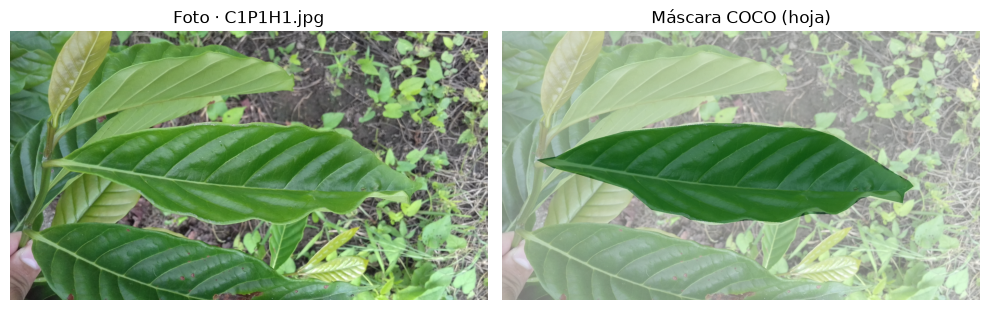

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_sample_leaf_mask_overlay.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole_sample_leaf_mask_overlay.png')

In [22]:
# sample_image, leaf_mask, sample_row
results_dir = repo_root / "experiments" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
mask_fig_path = results_dir / "rocole_sample_leaf_mask_overlay.png"

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample_image)
axes[0].set_title(f"Foto · {sample_row['File']}")
axes[0].axis("off")
axes[1].imshow(sample_image)
axes[1].imshow(leaf_mask, alpha=0.45, cmap="Greens")
axes[1].set_title("Máscara COCO (hoja)")
axes[1].axis("off")
fig.tight_layout()
fig.savefig(mask_fig_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", mask_fig_path)
mask_fig_path


## Índices solo dentro de la hoja

Los mapas ExG, NGRDI y VARI ya están; ahora media y desviación solo donde la máscara marca hoja.


In [23]:
# exg_map, ngrdi_map, vari_map, leaf_mask

masked_index_summary = {
    "exg": {
        "mean": float(exg_map[leaf_mask].mean()),
        "std": float(exg_map[leaf_mask].std()),
    },
    "ngrdi": {
        "mean": float(ngrdi_map[leaf_mask].mean()),
        "std": float(ngrdi_map[leaf_mask].std()),
    },
    "vari": {
        "mean": float(vari_map[leaf_mask].mean()),
        "std": float(vari_map[leaf_mask].std()),
    },
}

for name, stats in masked_index_summary.items():
    print(f"{name}: mean={stats['mean']:.4f} std={stats['std']:.4f}")
masked_index_summary


exg: mean=0.4661 std=0.1972
ngrdi: mean=0.2506 std=0.0791
vari: mean=0.3486 std=0.0765


{'exg': {'mean': 0.4660838136274945, 'std': 0.19724263125473318},
 'ngrdi': {'mean': 0.2505761553664457, 'std': 0.07905320717247015},
 'vari': {'mean': 0.3485919335512058, 'std': 0.07651356308890896}}

## Gris recortado a la hoja

Para el GLCM enmascarado recortamos al bounding box de la máscara y ponemos en 0 lo que no es hoja; así el fondo lejano no entra en la textura.


In [24]:
# gray, leaf_mask

rows, cols = np.where(leaf_mask)
y0, y1 = int(rows.min()), int(rows.max()) + 1
x0, x1 = int(cols.min()), int(cols.max()) + 1
leaf_gray_crop = gray[y0:y1, x0:x1].copy()
crop_mask = leaf_mask[y0:y1, x0:x1]
# fuera de hoja dentro del bbox → 0 (constante)
leaf_gray_crop[~crop_mask] = 0

print("bbox:", (y0, y1, x0, x1))
print("forma crop:", leaf_gray_crop.shape)
print("min/max:", int(leaf_gray_crop.min()), int(leaf_gray_crop.max()))
leaf_gray_crop


bbox: (393, 824, 146, 1764)
forma crop: (431, 1618)
min/max: 0 247


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(431, 1618), dtype=uint8)

## Cuantizar el recorte a 32 niveles

Igual que en la foto completa: bajamos a 32 niveles para que la matriz GLCM sea manejable.


In [25]:
# leaf_gray_crop, gray_level_count

leaf_quantized_gray = (
    leaf_gray_crop.astype(np.float64) / 255.0 * (gray_level_count - 1)
).astype(np.uint8)

print("niveles:", gray_level_count)
print("valores únicos:", len(np.unique(leaf_quantized_gray)))
print("min/max:", int(leaf_quantized_gray.min()), int(leaf_quantized_gray.max()))
leaf_quantized_gray


niveles: 32
valores únicos: 30
min/max: 0 30


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(431, 1618), dtype=uint8)

## GLCM del recorte enmascarado

Repetimos la matriz de coocurrencia con distancia 1 y ángulo 0, ahora sobre el recorte de la hoja.


In [26]:
# leaf_quantized_gray, gray_level_count

leaf_glcm = graycomatrix(
    leaf_quantized_gray,
    distances=[1],
    angles=[0],
    levels=gray_level_count,
)

print("forma leaf_glcm:", leaf_glcm.shape)
leaf_glcm


forma leaf_glcm: (32, 32, 1, 1)


array([[[[245857]],

        [[     0]],

        [[     0]],

        ...,

        [[     0]],

        [[     0]],

        [[     0]]],


       [[[     0]],

        [[     0]],

        [[     0]],

        ...,

        [[     0]],

        [[     0]],

        [[     0]]],


       [[[     0]],

        [[     0]],

        [[     0]],

        ...,

        [[     0]],

        [[     0]],

        [[     0]]],


       ...,


       [[[     0]],

        [[     0]],

        [[     0]],

        ...,

        [[     8]],

        [[     1]],

        [[     0]]],


       [[[     0]],

        [[     0]],

        [[     0]],

        ...,

        [[     0]],

        [[     0]],

        [[     0]]],


       [[[     0]],

        [[     0]],

        [[     0]],

        ...,

        [[     0]],

        [[     0]],

        [[     0]]]], shape=(32, 32, 1, 1), dtype=uint32)

## Textura GLCM solo en la hoja

Los mismos tres números que ya tenemos para la foto completa: contraste, homogeneidad y energía del recorte.


In [27]:
# leaf_glcm

masked_glcm_summary = {
    "contrast": float(graycoprops(leaf_glcm, "contrast")[0, 0]),
    "homogeneity": float(graycoprops(leaf_glcm, "homogeneity")[0, 0]),
    "energy": float(graycoprops(leaf_glcm, "energy")[0, 0]),
}

print(masked_glcm_summary)
masked_glcm_summary


{'contrast': 0.6843170088115398, 'homogeneity': 0.8959425855242532, 'energy': 0.3815731978319883}


{'contrast': 0.6843170088115398,
 'homogeneity': 0.8959425855242532,
 'energy': 0.3815731978319883}

## Completa vs máscara COCO

Ponemos lado a lado lo medido en la foto entera y lo medido solo en la hoja, para ver qué se mueve.


In [28]:
# index_summary, masked_index_summary
# glcm_contrast, glcm_homogeneity, glcm_energy, masked_glcm_summary

feature_comparison = pd.DataFrame(
    [
        {
            "feature": "exg_mean",
            "full_image": index_summary["exg"]["mean"],
            "coco_mask": masked_index_summary["exg"]["mean"],
        },
        {
            "feature": "exg_std",
            "full_image": index_summary["exg"]["std"],
            "coco_mask": masked_index_summary["exg"]["std"],
        },
        {
            "feature": "ngrdi_mean",
            "full_image": index_summary["ngrdi"]["mean"],
            "coco_mask": masked_index_summary["ngrdi"]["mean"],
        },
        {
            "feature": "ngrdi_std",
            "full_image": index_summary["ngrdi"]["std"],
            "coco_mask": masked_index_summary["ngrdi"]["std"],
        },
        {
            "feature": "vari_mean",
            "full_image": index_summary["vari"]["mean"],
            "coco_mask": masked_index_summary["vari"]["mean"],
        },
        {
            "feature": "vari_std",
            "full_image": index_summary["vari"]["std"],
            "coco_mask": masked_index_summary["vari"]["std"],
        },
        {
            "feature": "glcm_contrast",
            "full_image": glcm_contrast,
            "coco_mask": masked_glcm_summary["contrast"],
        },
        {
            "feature": "glcm_homogeneity",
            "full_image": glcm_homogeneity,
            "coco_mask": masked_glcm_summary["homogeneity"],
        },
        {
            "feature": "glcm_energy",
            "full_image": glcm_energy,
            "coco_mask": masked_glcm_summary["energy"],
        },
    ]
)

print(feature_comparison.to_string(index=False))


         feature  full_image  coco_mask
        exg_mean    0.261530   0.466084
         exg_std    0.206835   0.197243
      ngrdi_mean    0.141426   0.250576
       ngrdi_std    0.118705   0.079053
       vari_mean    0.210467   0.348592
        vari_std    0.170665   0.076514
   glcm_contrast    0.603388   0.684317
glcm_homogeneity    0.798073   0.895943
     glcm_energy    0.161943   0.381573


## Conclusiones

En la misma foto de train, al medir solo la hoja con la máscara COCO los índices dejan de mezclarse con el fondo y la textura GLCM ya no “ve” pared o suelo; el borde hoja–constante del recorte puede empujar un poco el contraste. Es una sola hoja: el inventario y los modelos siguen después.


## Piloto: tres sanas y tres afectadas (train), dos protocolos

Antes del inventario completo, medimos color y textura en un puñado de hojas de **train**: tres sanas y tres afectadas. Las **mismas** seis fotos se miden dos veces: solo hoja (máscara COCO) y foto entera (sin segmentar). No es el dataset entero; es un chequeo de cuánto cambia el número al quitar el fondo.


## Tres hojas sanas de train

Sacamos tres fotos con `Binary.Label == healthy` solo del split de aprender, con la semilla fija del cuaderno.


In [29]:
if "train_rows" not in globals():
    train_rows = rocole_index.loc[rocole_index["split"] == "train"].reset_index(drop=True)

healthy_train_sample = (
    train_rows.loc[train_rows["Binary.Label"] == "healthy"]
    .sample(n=3, random_state=seed)
    .reset_index(drop=True)
)

print("healthy_train_sample:", len(healthy_train_sample))
healthy_train_sample[["File", "Binary.Label", "split", "photo_path"]]


healthy_train_sample: 3


,File,Binary.Label,split,photo_path
0,C4P39H1.jpg,healthy,train,data/curated/rocole/photos/C4P39H1.jpg
1,C9P20E2.jpg,healthy,train,data/curated/rocole/photos/C9P20E2.jpg
2,C1P6H1.jpg,healthy,train,data/curated/rocole/photos/C1P6H1.jpg


## Tres hojas afectadas de train

Igual que arriba, pero con `Binary.Label == unhealthy`: tres fotos de aprender afectadas.


In [30]:
# train_rows, seed

unhealthy_train_sample = (
    train_rows.loc[train_rows["Binary.Label"] == "unhealthy"]
    .sample(n=3, random_state=seed)
    .reset_index(drop=True)
)

print("unhealthy_train_sample:", len(unhealthy_train_sample))
unhealthy_train_sample[["File", "Binary.Label", "split", "photo_path"]]


unhealthy_train_sample: 3


,File,Binary.Label,split,photo_path
0,C1P26H2.jpg,unhealthy,train,data/curated/rocole/photos/C1P26H2.jpg
1,C6P40E2.jpg,unhealthy,train,data/curated/rocole/photos/C6P40E2.jpg
2,C12P22H2.jpg,unhealthy,train,data/curated/rocole/photos/C12P22H2.jpg


## Unir el puñado piloto

Juntamos las tres sanas y las tres afectadas en una sola mesa de seis filas: `pilot_train_rows`.


In [31]:
# healthy_train_sample, unhealthy_train_sample

pilot_train_rows = pd.concat(
    [healthy_train_sample, unhealthy_train_sample],
    ignore_index=True,
)

print("pilot_train_rows:", len(pilot_train_rows))
print(pilot_train_rows["Binary.Label"].value_counts().to_string())
pilot_train_rows[["File", "Binary.Label", "split"]]


pilot_train_rows: 6
Binary.Label
healthy      3
unhealthy    3


,File,Binary.Label,split
0,C4P39H1.jpg,healthy,train
1,C9P20E2.jpg,healthy,train
2,C1P6H1.jpg,healthy,train
3,C1P26H2.jpg,unhealthy,train
4,C6P40E2.jpg,unhealthy,train
5,C12P22H2.jpg,unhealthy,train


## Funciones de resumen RGB y GLCM (con o sin máscara)

Si pasamos máscara, medimos solo la hoja (índices en píxeles de hoja; GLCM en bbox con fuera-de-hoja en 0). Si `leaf_mask` es `None`, el promedio y el GLCM usan **toda** la foto, igual que en la exploración previa del cuaderno.


In [32]:
# eps, gray_level_count; graycomatrix / graycoprops ya importados arriba

def extract_rgb_summary(image_rgb_or_pil, leaf_mask=None):
    """Media y std de ExG, NGRDI y VARI; leaf_mask=None → foto completa."""
    if hasattr(image_rgb_or_pil, "convert"):
        image_rgb = np.asarray(image_rgb_or_pil.convert("RGB"), dtype=np.float64)
    else:
        image_rgb = np.asarray(image_rgb_or_pil, dtype=np.float64)

    red_channel = image_rgb[:, :, 0]
    green_channel = image_rgb[:, :, 1]
    blue_channel = image_rgb[:, :, 2]

    channel_sum = red_channel + green_channel + blue_channel + eps
    r = red_channel / channel_sum
    g = green_channel / channel_sum
    b = blue_channel / channel_sum
    exg_map = 2.0 * g - r - b
    ngrdi_map = (green_channel - red_channel) / (green_channel + red_channel + eps)
    vari_map = (green_channel - red_channel) / (
        green_channel + red_channel - blue_channel + eps
    )

    # sin máscara: promediamos toda la foto
    if leaf_mask is None:
        return {
            "exg_mean": float(exg_map.mean()),
            "exg_std": float(exg_map.std()),
            "ngrdi_mean": float(ngrdi_map.mean()),
            "ngrdi_std": float(ngrdi_map.std()),
            "vari_mean": float(vari_map.mean()),
            "vari_std": float(vari_map.std()),
        }

    return {
        "exg_mean": float(exg_map[leaf_mask].mean()),
        "exg_std": float(exg_map[leaf_mask].std()),
        "ngrdi_mean": float(ngrdi_map[leaf_mask].mean()),
        "ngrdi_std": float(ngrdi_map[leaf_mask].std()),
        "vari_mean": float(vari_map[leaf_mask].mean()),
        "vari_std": float(vari_map[leaf_mask].std()),
    }


def extract_glcm_summary(gray_or_pil, leaf_mask=None):
    """GLCM d=1, ángulo 0, 32 niveles; leaf_mask=None → gris completa."""
    if hasattr(gray_or_pil, "convert"):
        gray = np.asarray(gray_or_pil.convert("L"), dtype=np.uint8)
    else:
        gray = np.asarray(gray_or_pil, dtype=np.uint8)

    if leaf_mask is None:
        # foto completa: sin bbox ni ceros artificiales
        work_gray = gray
    else:
        rows, cols = np.where(leaf_mask)
        y0, y1 = int(rows.min()), int(rows.max()) + 1
        x0, x1 = int(cols.min()), int(cols.max()) + 1
        work_gray = gray[y0:y1, x0:x1].copy()
        crop_mask = leaf_mask[y0:y1, x0:x1]
        work_gray[~crop_mask] = 0

    quantized_gray = (
        work_gray.astype(np.float64) / 255.0 * (gray_level_count - 1)
    ).astype(np.uint8)

    glcm = graycomatrix(
        quantized_gray,
        distances=[1],
        angles=[0],
        levels=gray_level_count,
    )
    return {
        "glcm_contrast": float(graycoprops(glcm, "contrast")[0, 0]),
        "glcm_homogeneity": float(graycoprops(glcm, "homogeneity")[0, 0]),
        "glcm_energy": float(graycoprops(glcm, "energy")[0, 0]),
    }


extract_rgb_summary, extract_glcm_summary


(<function __main__.extract_rgb_summary(image_rgb_or_pil, leaf_mask=None)>,
 <function __main__.extract_glcm_summary(gray_or_pil, leaf_mask=None)>)

## Cargar la máscara COCO por File

En el JSON, `file_name` es una URL; emparejamos si termina en el `File` del índice (igual que en la sección COCO). Devolvemos la unión de anotaciones Leaf.


In [33]:
# coco: anotaciones RoCoLe ya cargadas

def load_coco_leaf_mask(coco, file_name, height, width):
    """Máscara Leaf (OR) emparejando file_name del JSON por sufijo File."""
    matched_images = [
        img
        for img in coco.loadImgs(coco.getImgIds())
        if img["file_name"].endswith(file_name)
    ]
    if len(matched_images) != 1:
        raise ValueError(
            f"esperaba 1 imagen COCO para {file_name}, hay {len(matched_images)}"
        )

    coco_image = matched_images[0]
    # categoría Leaf = 1; imgIds en lista (ids Labelbox son strings)
    ann_ids = coco.getAnnIds(imgIds=[coco_image["id"]], catIds=[1])
    annotations = coco.loadAnns(ann_ids)
    if len(annotations) < 1:
        raise ValueError(f"sin anotaciones Leaf para {file_name}")

    leaf_mask = None
    for annotation in annotations:
        mask_i = coco.annToMask(annotation).astype(bool)
        leaf_mask = mask_i if leaf_mask is None else (leaf_mask | mask_i)

    if leaf_mask.shape != (height, width):
        raise ValueError(
            f"máscara {leaf_mask.shape} vs imagen {(height, width)} para {file_name}"
        )
    return leaf_mask


load_coco_leaf_mask


<function __main__.load_coco_leaf_mask(coco, file_name, height, width)>

## Features con máscara COCO, fila a fila

Primero sacamos color y textura **solo con máscara COCO** en las seis filas de `pilot_train_rows`. Si falta máscara o falla la lectura, NaN en features y mensaje en `error_masked`.


In [34]:
# pilot_train_rows, coco, repo_root
# extract_rgb_summary, extract_glcm_summary, load_coco_leaf_mask

feature_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "vari_mean",
    "vari_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]

pilot_masked_feature_rows = []
for _, row in pilot_train_rows.iterrows():
    feature_row = {
        "File": row["File"],
        "Binary.Label": row["Binary.Label"],
        "split": row["split"],
        "photo_path": row["photo_path"],
        "error_masked": None,
    }
    for column_name in feature_columns:
        feature_row[column_name] = np.nan

    try:
        photo_path = repo_root / row["photo_path"]
        sample_image = Image.open(photo_path).convert("RGB")
        height, width = sample_image.size[1], sample_image.size[0]
        leaf_mask = load_coco_leaf_mask(coco, row["File"], height, width)
        rgb_summary = extract_rgb_summary(sample_image, leaf_mask)
        glcm_summary = extract_glcm_summary(sample_image, leaf_mask)
        feature_row.update(rgb_summary)
        feature_row.update(glcm_summary)
    except Exception as exc:
        # fallo de máscara o lectura: NaN en features, mensaje en error_masked
        feature_row["error_masked"] = str(exc)

    pilot_masked_feature_rows.append(feature_row)

print("pilot_masked_feature_rows:", len(pilot_masked_feature_rows))
print("con error_masked:", sum(1 for r in pilot_masked_feature_rows if r["error_masked"]))
pilot_masked_feature_rows


pilot_masked_feature_rows: 6
con error_masked: 0


[{'File': 'C4P39H1.jpg',
  'Binary.Label': 'healthy',
  'split': 'train',
  'photo_path': 'data/curated/rocole/photos/C4P39H1.jpg',
  'error_masked': None,
  'exg_mean': 0.8744595304596365,
  'exg_std': 0.19569153140674392,
  'ngrdi_mean': 0.2794048023508362,
  'ngrdi_std': 0.08708880751607716,
  'vari_mean': 0.28566796505150605,
  'vari_std': 0.08371673104565851,
  'glcm_contrast': 0.44470972731581965,
  'glcm_homogeneity': 0.9660850631584,
  'glcm_energy': 0.4864409279311582},
 {'File': 'C9P20E2.jpg',
  'Binary.Label': 'healthy',
  'split': 'train',
  'photo_path': 'data/curated/rocole/photos/C9P20E2.jpg',
  'error_masked': None,
  'exg_mean': 0.1395306234083355,
  'exg_std': 0.06786396339123582,
  'ngrdi_mean': 0.07407329807979936,
  'ngrdi_std': 0.0494639227213861,
  'vari_mean': 0.12486284912785092,
  'vari_std': 0.08042578287076373,
  'glcm_contrast': 0.6538022756158083,
  'glcm_homogeneity': 0.9478603198316743,
  'glcm_energy': 0.47559226230700413},
 {'File': 'C1P6H1.jpg',
  'Bi

## Tabla del piloto con máscara

Pasamos la lista enmascarada a un DataFrame: `pilot_masked_feature_table`.


In [35]:
# pilot_masked_feature_rows: lista de dicts del bucle con máscara

pilot_masked_feature_table = pd.DataFrame(pilot_masked_feature_rows)

print("filas:", len(pilot_masked_feature_table))
print("columnas:", list(pilot_masked_feature_table.columns))
pilot_masked_feature_table


filas: 6
columnas: ['File', 'Binary.Label', 'split', 'photo_path', 'error_masked', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,Binary.Label,split,photo_path,error_masked,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C4P39H1.jpg,healthy,train,data/curated/rocole/photos/C4P39H1.jpg,None,0.874460,0.195692,0.279405,0.087089,0.285668,0.083717,0.444710,0.966085,0.486441
1,C9P20E2.jpg,healthy,train,data/curated/rocole/photos/C9P20E2.jpg,None,0.139531,0.067864,0.074073,0.049464,0.124863,0.080426,0.653802,0.947860,0.475592
2,C1P6H1.jpg,healthy,train,data/curated/rocole/photos/C1P6H1.jpg,None,0.464751,0.155891,0.174130,0.044048,0.219823,0.044840,0.934725,0.884312,0.397183
3,C1P26H2.jpg,unhealthy,train,data/curated/rocole/photos/C1P26H2.jpg,None,0.381277,0.136840,0.181763,0.087861,0.253830,0.121603,0.462628,0.905025,0.379794
4,C6P40E2.jpg,unhealthy,train,data/curated/rocole/photos/C6P40E2.jpg,None,0.154308,0.050862,0.095024,0.038281,0.166206,0.069049,0.769670,0.906093,0.405603
5,C12P22H2.jpg,unhealthy,train,data/curated/rocole/photos/C12P22H2.jpg,None,0.709865,0.319958,0.299227,0.115215,0.347977,0.104489,0.660764,0.914883,0.346837


## Features en foto completa, fila a fila

Ahora las **mismas** seis fotos, midiendo RGB+GLCM sobre la imagen entera (`leaf_mask=None`). Este protocolo no depende de COCO.


In [36]:
# pilot_train_rows, repo_root, extract_rgb_summary, extract_glcm_summary
# feature_columns (misma lista que el protocolo enmascarado)

pilot_full_feature_rows = []
for _, row in pilot_train_rows.iterrows():
    feature_row = {
        "File": row["File"],
        "Binary.Label": row["Binary.Label"],
        "split": row["split"],
        "photo_path": row["photo_path"],
        "error_full": None,
    }
    for column_name in feature_columns:
        feature_row[column_name] = np.nan

    try:
        photo_path = repo_root / row["photo_path"]
        sample_image = Image.open(photo_path).convert("RGB")
        # sin máscara: misma API, leaf_mask=None
        rgb_summary = extract_rgb_summary(sample_image, leaf_mask=None)
        glcm_summary = extract_glcm_summary(sample_image, leaf_mask=None)
        feature_row.update(rgb_summary)
        feature_row.update(glcm_summary)
    except Exception as exc:
        # fallo de lectura: NaN en features, mensaje en error_full
        feature_row["error_full"] = str(exc)

    pilot_full_feature_rows.append(feature_row)

print("pilot_full_feature_rows:", len(pilot_full_feature_rows))
print("con error_full:", sum(1 for r in pilot_full_feature_rows if r["error_full"]))
pilot_full_feature_rows


pilot_full_feature_rows: 6
con error_full: 0


[{'File': 'C4P39H1.jpg',
  'Binary.Label': 'healthy',
  'split': 'train',
  'photo_path': 'data/curated/rocole/photos/C4P39H1.jpg',
  'error_full': None,
  'exg_mean': 0.3370002238841865,
  'exg_std': 0.44827572404535654,
  'ngrdi_mean': 0.06184448892257006,
  'ngrdi_std': 0.20287277315941196,
  'vari_mean': -17902.525671823332,
  'vari_std': 2689948.542409861,
  'glcm_contrast': 5.770472677669188,
  'glcm_homogeneity': 0.6798011513735631,
  'glcm_energy': 0.12259087704571575},
 {'File': 'C9P20E2.jpg',
  'Binary.Label': 'healthy',
  'split': 'train',
  'photo_path': 'data/curated/rocole/photos/C9P20E2.jpg',
  'error_full': None,
  'exg_mean': 0.22575863753359676,
  'exg_std': 0.19879282853059713,
  'ngrdi_mean': 0.11029882454281978,
  'ngrdi_std': 0.12862384149750153,
  'vari_mean': 0.16172787534689848,
  'vari_std': 0.185346002804048,
  'glcm_contrast': 0.3926266180175484,
  'glcm_homogeneity': 0.8759798438604296,
  'glcm_energy': 0.1712077671115971},
 {'File': 'C1P6H1.jpg',
  'Binary

## Tabla del piloto sin máscara

Pasamos la lista de foto completa a un DataFrame: `pilot_full_feature_table`.


In [37]:
# pilot_full_feature_rows: lista de dicts del bucle sin máscara

pilot_full_feature_table = pd.DataFrame(pilot_full_feature_rows)

print("filas:", len(pilot_full_feature_table))
print("columnas:", list(pilot_full_feature_table.columns))
pilot_full_feature_table


filas: 6
columnas: ['File', 'Binary.Label', 'split', 'photo_path', 'error_full', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,Binary.Label,split,photo_path,error_full,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C4P39H1.jpg,healthy,train,data/curated/rocole/photos/C4P39H1.jpg,None,0.337000,0.448276,0.061844,0.202873,-17902.525672,2.689949e+06,5.770473,0.679801,0.122591
1,C9P20E2.jpg,healthy,train,data/curated/rocole/photos/C9P20E2.jpg,None,0.225759,0.198793,0.110299,0.128624,0.161728,1.853460e-01,0.392627,0.875980,0.171208
2,C1P6H1.jpg,healthy,train,data/curated/rocole/photos/C1P6H1.jpg,None,0.237375,0.234373,0.121774,0.121374,169.718402,1.841423e+05,0.730441,0.781106,0.155509
3,C1P26H2.jpg,unhealthy,train,data/curated/rocole/photos/C1P26H2.jpg,None,0.326664,0.230668,0.167967,0.129965,0.240261,1.864388e-01,0.507202,0.827242,0.161881
4,C6P40E2.jpg,unhealthy,train,data/curated/rocole/photos/C6P40E2.jpg,None,0.170079,0.177313,0.082253,0.111769,21050.477385,6.687759e+06,0.586260,0.817209,0.169602
5,C12P22H2.jpg,unhealthy,train,data/curated/rocole/photos/C12P22H2.jpg,None,0.417856,0.395199,0.158561,0.175316,0.180965,2.055733e-01,0.398405,0.858995,0.177192


## Comparar máscara vs foto completa

Juntamos las dos mesas por `File` para leer lado a lado: mismas features con sufijo `_masked` y `_full`.


In [38]:
# pilot_masked_feature_table, pilot_full_feature_table, feature_columns

id_columns = ["File", "Binary.Label", "split", "photo_path"]
masked_part = pilot_masked_feature_table[
    id_columns + feature_columns + ["error_masked"]
].rename(columns={name: f"{name}_masked" for name in feature_columns})
full_part = pilot_full_feature_table[
    ["File"] + feature_columns + ["error_full"]
].rename(columns={name: f"{name}_full" for name in feature_columns})

pilot_compare_table = masked_part.merge(full_part, on="File", how="inner")

print("filas:", len(pilot_compare_table))
print("columnas:", list(pilot_compare_table.columns))
pilot_compare_table


filas: 6
columnas: ['File', 'Binary.Label', 'split', 'photo_path', 'exg_mean_masked', 'exg_std_masked', 'ngrdi_mean_masked', 'ngrdi_std_masked', 'vari_mean_masked', 'vari_std_masked', 'glcm_contrast_masked', 'glcm_homogeneity_masked', 'glcm_energy_masked', 'error_masked', 'exg_mean_full', 'exg_std_full', 'ngrdi_mean_full', 'ngrdi_std_full', 'vari_mean_full', 'vari_std_full', 'glcm_contrast_full', 'glcm_homogeneity_full', 'glcm_energy_full', 'error_full']


,File,Binary.Label,split,photo_path,exg_mean_masked,exg_std_masked,ngrdi_mean_masked,ngrdi_std_masked,vari_mean_masked,vari_std_masked,...,exg_mean_full,exg_std_full,ngrdi_mean_full,ngrdi_std_full,vari_mean_full,vari_std_full,glcm_contrast_full,glcm_homogeneity_full,glcm_energy_full,error_full
0,C4P39H1.jpg,healthy,train,data/curated/rocole/photos/C4P39H1.jpg,0.874460,0.195692,0.279405,0.087089,0.285668,0.083717,...,0.337000,0.448276,0.061844,0.202873,-17902.525672,2.689949e+06,5.770473,0.679801,0.122591,None
1,C9P20E2.jpg,healthy,train,data/curated/rocole/photos/C9P20E2.jpg,0.139531,0.067864,0.074073,0.049464,0.124863,0.080426,...,0.225759,0.198793,0.110299,0.128624,0.161728,1.853460e-01,0.392627,0.875980,0.171208,None
2,C1P6H1.jpg,healthy,train,data/curated/rocole/photos/C1P6H1.jpg,0.464751,0.155891,0.174130,0.044048,0.219823,0.044840,...,0.237375,0.234373,0.121774,0.121374,169.718402,1.841423e+05,0.730441,0.781106,0.155509,None
3,C1P26H2.jpg,unhealthy,train,data/curated/rocole/photos/C1P26H2.jpg,0.381277,0.136840,0.181763,0.087861,0.253830,0.121603,...,0.326664,0.230668,0.167967,0.129965,0.240261,1.864388e-01,0.507202,0.827242,0.161881,None
4,C6P40E2.jpg,unhealthy,train,data/curated/rocole/photos/C6P40E2.jpg,0.154308,0.050862,0.095024,0.038281,0.166206,0.069049,...,0.170079,0.177313,0.082253,0.111769,21050.477385,6.687759e+06,0.586260,0.817209,0.169602,None
5,C12P22H2.jpg,unhealthy,train,data/curated/rocole/photos/C12P22H2.jpg,0.709865,0.319958,0.299227,0.115215,0.347977,0.104489,...,0.417856,0.395199,0.158561,0.175316,0.180965,2.055733e-01,0.398405,0.858995,0.177192,None


## Diferencias full − masked

Restamos foto completa menos máscara en cada feature numérica para ver el tamaño del cambio por foto.


In [39]:
# pilot_compare_table, feature_columns

delta_rows = []
for _, row in pilot_compare_table.iterrows():
    delta_row = {
        "File": row["File"],
        "Binary.Label": row["Binary.Label"],
        "split": row["split"],
    }
    for column_name in feature_columns:
        delta_row[f"{column_name}_delta"] = (
            row[f"{column_name}_full"] - row[f"{column_name}_masked"]
        )
    delta_rows.append(delta_row)

pilot_feature_delta_table = pd.DataFrame(delta_rows)

print("filas:", len(pilot_feature_delta_table))
print("columnas:", list(pilot_feature_delta_table.columns))
pilot_feature_delta_table


filas: 6
columnas: ['File', 'Binary.Label', 'split', 'exg_mean_delta', 'exg_std_delta', 'ngrdi_mean_delta', 'ngrdi_std_delta', 'vari_mean_delta', 'vari_std_delta', 'glcm_contrast_delta', 'glcm_homogeneity_delta', 'glcm_energy_delta']


,File,Binary.Label,split,exg_mean_delta,exg_std_delta,ngrdi_mean_delta,ngrdi_std_delta,vari_mean_delta,vari_std_delta,glcm_contrast_delta,glcm_homogeneity_delta,glcm_energy_delta
0,C4P39H1.jpg,healthy,train,-0.537459,0.252584,-0.217560,0.115784,-17902.811340,2.689948e+06,5.325763,-0.286284,-0.363850
1,C9P20E2.jpg,healthy,train,0.086228,0.130929,0.036226,0.079160,0.036865,1.049202e-01,-0.261176,-0.071880,-0.304384
2,C1P6H1.jpg,healthy,train,-0.227376,0.078482,-0.052355,0.077326,169.498578,1.841423e+05,-0.204283,-0.103206,-0.241674
3,C1P26H2.jpg,unhealthy,train,-0.054613,0.093828,-0.013795,0.042104,-0.013569,6.483581e-02,0.044574,-0.077783,-0.217914
4,C6P40E2.jpg,unhealthy,train,0.015771,0.126451,-0.012771,0.073488,21050.311180,6.687759e+06,-0.183410,-0.088884,-0.236001
5,C12P22H2.jpg,unhealthy,train,-0.292009,0.075241,-0.140667,0.060100,-0.167013,1.010846e-01,-0.262360,-0.055887,-0.169644


## Lectura del piloto (máscara vs completa)

En este puñado de seis hojas de train, mira `pilot_compare_table` y `pilot_feature_delta_table`: ¿los índices y el GLCM se mueven mucho al quitar la máscara? Es orientación de seis fotos de aprender, no una conclusión del dataset ni un ganador estadístico.


## Nota de decisión

El **experimento** puede reportar ambos protocolos (máscara COCO vs foto completa) para transparencia. El **modelo / pipeline de producción** principal se plantea **sin máscara** (sin segmentador). El inventario completo de features sigue después, fuera de este piloto.


## Inventario completo: RGB + GLCM sin máscara

Medimos color y textura en **todas** las fotos del índice (`rocole_index`), con el protocolo de producción: foto entera, sin segmentar. Primero un smoke de pocas filas de train; luego el barrido completo y el CSV en `data/featured/rocole/`.


## Protocolo de producción (foto completa)

Fijamos en un diccionario lo que usará el inventario: sin máscara, 32 niveles de gris, GLCM a distancia 1 y ángulo 0, y el mismo `eps` que arriba.


In [40]:
# eps, gray_level_count (ya fijados arriba en el cuaderno)

production_protocol = {
    "leaf_mask": None,
    "gray_level_count": 32,
    "distances": [1],
    "angles": [0],
    "eps": eps,
}

production_protocol


{'leaf_mask': None,
 'gray_level_count': 32,
 'distances': [1],
 'angles': [0],
 'eps': 1e-08}

## Columnas de features del inventario

Lista fija de medidas que deben salir de las extractoras: media y std de los tres índices RGB, más contraste, homogeneidad y energía GLCM. Las funciones del piloto ya devuelven std; aquí solo nombramos las columnas.


In [41]:
# extract_rgb_summary, extract_glcm_summary (piloto; ya incluyen mean y std)

feature_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "vari_mean",
    "vari_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]

feature_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'vari_mean',
 'vari_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

## Columnas de identidad que viajan con cada fila

Además de las features, cada fila del inventario lleva el archivo, el split, el grupo de enlace y las dos etiquetas del índice.


In [42]:
id_columns = [
    "File",
    "split",
    "link_group",
    "Binary.Label",
    "Multiclass.Label",
]

id_columns


['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label']

## Filas de smoke (train)

Para probar el camino sin recorrer las ~1481 fotos, reutilizamos `pilot_train_rows` si existe; si no, tomamos seis filas de train al azar con la semilla fija.


In [43]:
# pilot_train_rows (si el piloto corrió), train_rows / rocole_index, seed

if "pilot_train_rows" in globals() and len(pilot_train_rows) > 0:
    smoke_train_rows = pilot_train_rows.copy()
else:
    # respaldo: seis de train con semilla fija
    if "train_rows" not in globals():
        train_rows = rocole_index.loc[rocole_index["split"] == "train"].reset_index(
            drop=True
        )
    smoke_train_rows = train_rows.sample(n=6, random_state=seed).reset_index(drop=True)

print("smoke_train_rows:", len(smoke_train_rows))
print(smoke_train_rows["Binary.Label"].value_counts().to_string())
smoke_train_rows[id_columns]


smoke_train_rows: 6
Binary.Label
healthy      3
unhealthy    3


,File,split,link_group,Binary.Label,Multiclass.Label
0,C4P39H1.jpg,train,190,healthy,healthy
1,C9P20E2.jpg,train,333,healthy,healthy
2,C1P6H1.jpg,train,105,healthy,healthy
3,C1P26H2.jpg,train,91,unhealthy,rust_level_2
4,C6P40E2.jpg,train,254,unhealthy,red_spider_mite
5,C12P22H2.jpg,train,66,unhealthy,rust_level_1


## Smoke: features sin máscara, fila a fila

Sobre esas pocas filas de train medimos RGB+GLCM con `leaf_mask=None` (protocolo de producción). Si falla una foto, NaN en features y mensaje en `error`.


In [44]:
# smoke_train_rows, repo_root, production_protocol
# extract_rgb_summary, extract_glcm_summary, feature_columns, id_columns

smoke_feature_rows = []
for _, row in smoke_train_rows.iterrows():
    feature_row = {column_name: row[column_name] for column_name in id_columns}
    feature_row["error"] = None
    for column_name in feature_columns:
        feature_row[column_name] = np.nan

    try:
        photo_path = repo_root / row["photo_path"]
        sample_image = Image.open(photo_path).convert("RGB")
        # protocolo producción: sin máscara
        rgb_summary = extract_rgb_summary(
            sample_image, leaf_mask=production_protocol["leaf_mask"]
        )
        glcm_summary = extract_glcm_summary(
            sample_image, leaf_mask=production_protocol["leaf_mask"]
        )
        feature_row.update(rgb_summary)
        feature_row.update(glcm_summary)
    except Exception as exc:
        feature_row["error"] = str(exc)

    smoke_feature_rows.append(feature_row)

print("smoke_feature_rows:", len(smoke_feature_rows))
print("con error:", sum(1 for r in smoke_feature_rows if r["error"]))
smoke_feature_rows


smoke_feature_rows: 6
con error: 0


[{'File': 'C4P39H1.jpg',
  'split': 'train',
  'link_group': 190,
  'Binary.Label': 'healthy',
  'Multiclass.Label': 'healthy',
  'error': None,
  'exg_mean': 0.3370002238841865,
  'exg_std': 0.44827572404535654,
  'ngrdi_mean': 0.06184448892257006,
  'ngrdi_std': 0.20287277315941196,
  'vari_mean': -17902.525671823332,
  'vari_std': 2689948.542409861,
  'glcm_contrast': 5.770472677669188,
  'glcm_homogeneity': 0.6798011513735631,
  'glcm_energy': 0.12259087704571575},
 {'File': 'C9P20E2.jpg',
  'split': 'train',
  'link_group': 333,
  'Binary.Label': 'healthy',
  'Multiclass.Label': 'healthy',
  'error': None,
  'exg_mean': 0.22575863753359676,
  'exg_std': 0.19879282853059713,
  'ngrdi_mean': 0.11029882454281978,
  'ngrdi_std': 0.12862384149750153,
  'vari_mean': 0.16172787534689848,
  'vari_std': 0.185346002804048,
  'glcm_contrast': 0.3926266180175484,
  'glcm_homogeneity': 0.8759798438604296,
  'glcm_energy': 0.1712077671115971},
 {'File': 'C1P6H1.jpg',
  'split': 'train',
  'link

## Tabla smoke y chequeo de columnas / finitos

Pasamos el smoke a DataFrame y comprobamos que estén todas las columnas pedidas y que, sin error, los números sean finitos.


In [45]:
# smoke_feature_rows, feature_columns, id_columns

smoke_feature_table = pd.DataFrame(smoke_feature_rows)

expected_columns = id_columns + feature_columns + ["error"]
missing_columns = [
    name for name in expected_columns if name not in smoke_feature_table.columns
]
assert missing_columns == [], f"faltan columnas: {missing_columns}"

ok_mask = smoke_feature_table["error"].isna()
finite_ok = True
if ok_mask.any():
    feature_block = smoke_feature_table.loc[ok_mask, feature_columns]
    finite_ok = bool(np.isfinite(feature_block.to_numpy(dtype=float)).all())

print("filas:", len(smoke_feature_table))
print("columnas esperadas ok:", missing_columns == [])
print("finitos en filas sin error:", finite_ok)
smoke_feature_table


filas: 6
columnas esperadas ok: True
finitos en filas sin error: True


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C4P39H1.jpg,train,190,healthy,healthy,None,0.337000,0.448276,0.061844,0.202873,-17902.525672,2.689949e+06,5.770473,0.679801,0.122591
1,C9P20E2.jpg,train,333,healthy,healthy,None,0.225759,0.198793,0.110299,0.128624,0.161728,1.853460e-01,0.392627,0.875980,0.171208
2,C1P6H1.jpg,train,105,healthy,healthy,None,0.237375,0.234373,0.121774,0.121374,169.718402,1.841423e+05,0.730441,0.781106,0.155509
3,C1P26H2.jpg,train,91,unhealthy,rust_level_2,None,0.326664,0.230668,0.167967,0.129965,0.240261,1.864388e-01,0.507202,0.827242,0.161881
4,C6P40E2.jpg,train,254,unhealthy,red_spider_mite,None,0.170079,0.177313,0.082253,0.111769,21050.477385,6.687759e+06,0.586260,0.817209,0.169602
5,C12P22H2.jpg,train,66,unhealthy,rust_level_1,None,0.417856,0.395199,0.158561,0.175316,0.180965,2.055733e-01,0.398405,0.858995,0.177192


## Barrido completo del índice (sin máscara)

Recorremos **todas** las filas de `rocole_index` con el mismo protocolo de producción. Cada fallo queda en `error` y las features en NaN; no usamos máscaras ni miramos el test para elegir nada.


In [46]:
# rocole_index, repo_root, production_protocol
# extract_rgb_summary, extract_glcm_summary, feature_columns, id_columns

inventory_feature_rows = []
for _, row in tqdm(
    rocole_index.iterrows(),
    total=len(rocole_index),
    desc="inventario RGB+GLCM",
):
    feature_row = {column_name: row[column_name] for column_name in id_columns}
    feature_row["error"] = None
    for column_name in feature_columns:
        feature_row[column_name] = np.nan

    try:
        photo_path = repo_root / row["photo_path"]
        sample_image = Image.open(photo_path).convert("RGB")
        rgb_summary = extract_rgb_summary(
            sample_image, leaf_mask=production_protocol["leaf_mask"]
        )
        glcm_summary = extract_glcm_summary(
            sample_image, leaf_mask=production_protocol["leaf_mask"]
        )
        feature_row.update(rgb_summary)
        feature_row.update(glcm_summary)
    except Exception as exc:
        feature_row["error"] = str(exc)

    inventory_feature_rows.append(feature_row)

print("inventory_feature_rows:", len(inventory_feature_rows))
print(
    "con error:",
    sum(1 for r in inventory_feature_rows if r["error"] is not None),
)


inventario RGB+GLCM:   0%|          | 0/1481 [00:00<?, ?it/s]

inventario RGB+GLCM:   0%|          | 1/1481 [00:00<05:00,  4.92it/s]

inventario RGB+GLCM:   0%|          | 2/1481 [00:00<05:01,  4.91it/s]

inventario RGB+GLCM:   0%|          | 3/1481 [00:00<05:09,  4.77it/s]

inventario RGB+GLCM:   0%|          | 4/1481 [00:00<05:06,  4.81it/s]

inventario RGB+GLCM:   0%|          | 5/1481 [00:01<05:05,  4.83it/s]

... (1,222 outputs left out)

inventario RGB+GLCM: 100%|█████████▉| 1479/1481 [07:18<00:00,  4.72it/s]

inventario RGB+GLCM: 100%|██████████| 1481/1481 [07:19<00:00,  5.55it/s]

inventario RGB+GLCM: 100%|██████████| 1481/1481 [07:19<00:00,  3.37it/s]

inventory_feature_rows: 1481
con error: 0


## Mesa de features del inventario

Convertimos la lista del barrido en un DataFrame: `rgb_glcm_features`.


In [47]:
# inventory_feature_rows

rgb_glcm_features = pd.DataFrame(inventory_feature_rows)

print("filas:", len(rgb_glcm_features))
print("columnas:", list(rgb_glcm_features.columns))
rgb_glcm_features.head()


filas: 1481
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,None,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,None,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,None,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,None,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,None,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


## Chequeo de filas del inventario

Comprobamos que haya una fila por foto del índice, que los conteos por split cuadren y cuántas filas trajeron error.


In [48]:
# rgb_glcm_features, rocole_index

inventory_row_check = {
    "n_index": len(rocole_index),
    "n_features": len(rgb_glcm_features),
    "len_match": len(rgb_glcm_features) == len(rocole_index),
    "split_counts_index": rocole_index["split"].value_counts().to_dict(),
    "split_counts_features": rgb_glcm_features["split"].value_counts().to_dict(),
    "n_errors": int(rgb_glcm_features["error"].notna().sum()),
}

assert inventory_row_check["len_match"], (
    f"filas features {inventory_row_check['n_features']} "
    f"!= índice {inventory_row_check['n_index']}"
)

inventory_row_check


{'n_index': 1481,
 'n_features': 1481,
 'len_match': True,
 'split_counts_index': {'train': 1037, 'test': 226, 'val': 218},
 'split_counts_features': {'train': 1037, 'test': 226, 'val': 218},
 'n_errors': 0}

## Guardar el CSV de features

Escribimos `rgb_glcm_features.csv` en la carpeta featured de RoCoLe. No entrenamos nada aquí.


In [49]:
# rgb_glcm_features, featured_dir

features_csv_path = featured_dir / "rgb_glcm_features.csv"
rgb_glcm_features.to_csv(features_csv_path, index=False)

print("guardado:", features_csv_path)
print("existe:", features_csv_path.exists())
features_csv_path


guardado: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features.csv
existe: True


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/data/featured/rocole/rgb_glcm_features.csv')

## Conclusiones

Quedó un CSV de RGB+GLCM **sin máscara** para las ~1481 fotos del índice (mismo protocolo de producción del piloto full); el smoke de train y el chequeo de filas/errores confirman el camino antes de cualquier modelo.
